# Triangular relationships

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import time
from multiprocessing import Pool
import pandas as pd

from love import triangular_relationships as trirel
from love import triangular_perturbation as tripert
from love import triangular_perturbation_heatmap as triheat
from love import triangular_lyapunov_sensitivity_analysis as trisens

## Basic dynamics, phase plot and partner switching plots for a set of parameters

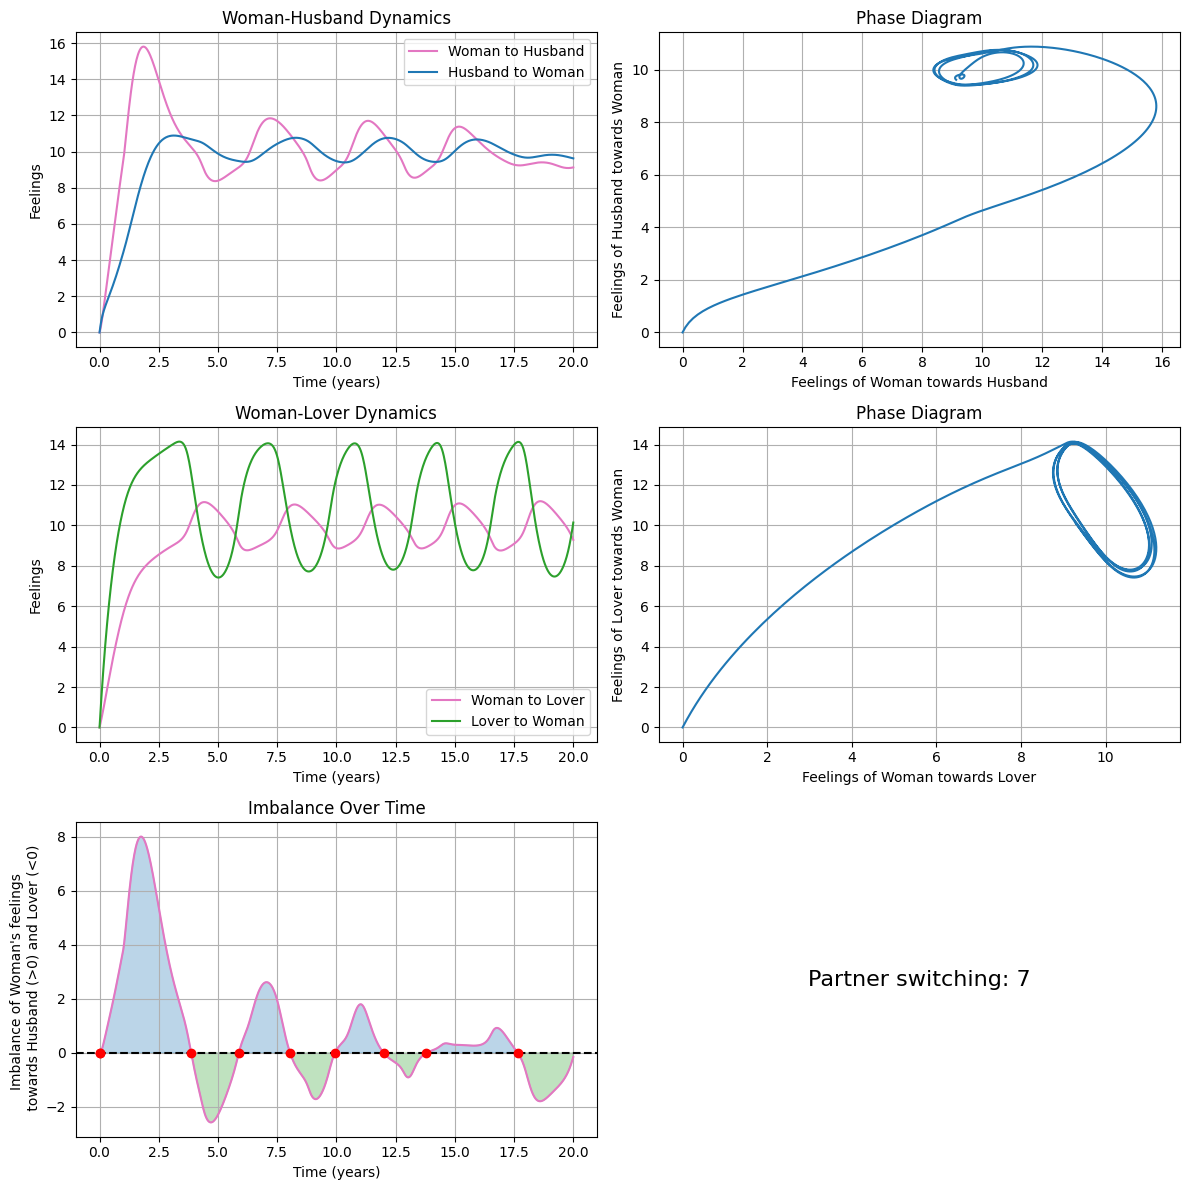

In [2]:
# Parameters w/ extensive comments
params = [
    2,    # alpha1: forgetting coefficient for Kathe (years^-1)
    1,    # alpha2: forgetting coefficient for Jules (years^-1)
    2,    # alpha3: forgetting coefficient for Jim (years^-1)
    1,    # beta21: reaction coefficient to love for Jules to Kathe's love(years^-1)
    8,    # beta12: reaction coefficient to love for Kathe to Jules love (years^-1)
    1,    # beta13: reaction coefficient to love for Kathe to Jim's love (years^-1)
    2,    # beta31: reaction coefficient to love for Jim to Kathe's love (years^-1)
    1,    # gamma1: reaction coefficient to appeal for Kathe (years^-1)
    0.5,  # gamma2: reaction coefficient to appeal for Jules (years^-1)
    1,    # gamma3: reaction coefficient to appeal for Jim (years^-1)
    0.0062,   # epsilon: sensitivity of reaction to love for Kathe (coupling constant)
    0.0285,    # delta: sensitivity of reaction to love for Jules and Jim (coupling constant)
    20,   # A1: appeal of Kathe (dimensionless)
    4,    # A2: appeal of Jules (dimensionless)
    5,    # A3: appeal of Jim (dimensionless)
    2.5,  # tauI12: insecurity threshold for Kathe's reaction to Jules' love
    10,   # sigmaL12: sensitivity of reaction to love for Kathe to Jules
    10.5, # sigmaI12: sensitivity of insecurity for Kathe to Jules
    9,    # tau_S: synergism threshold for Kathe
    1,    # sigmaS: sensitivity of synergism for Kathe
    0,    # tauP: platonicity threshold for Jules
    1,    # p: maximum platonicity for Jules
    1,    # sigmaP: sensitivity of platonicity for Jules
    9,    # tauI31: insecurity threshold for Jim's reaction to love
    10,   # sigmaL31: sensitivity of reaction to love for Jim
    1,    # sigmaI31: sensitivity of insecurity for Jim
    2,    # s: synergism coefficient for Kathe
]

trirel.default_triangular_plot()

## Plots for a perturbation of initial conditions or parameters

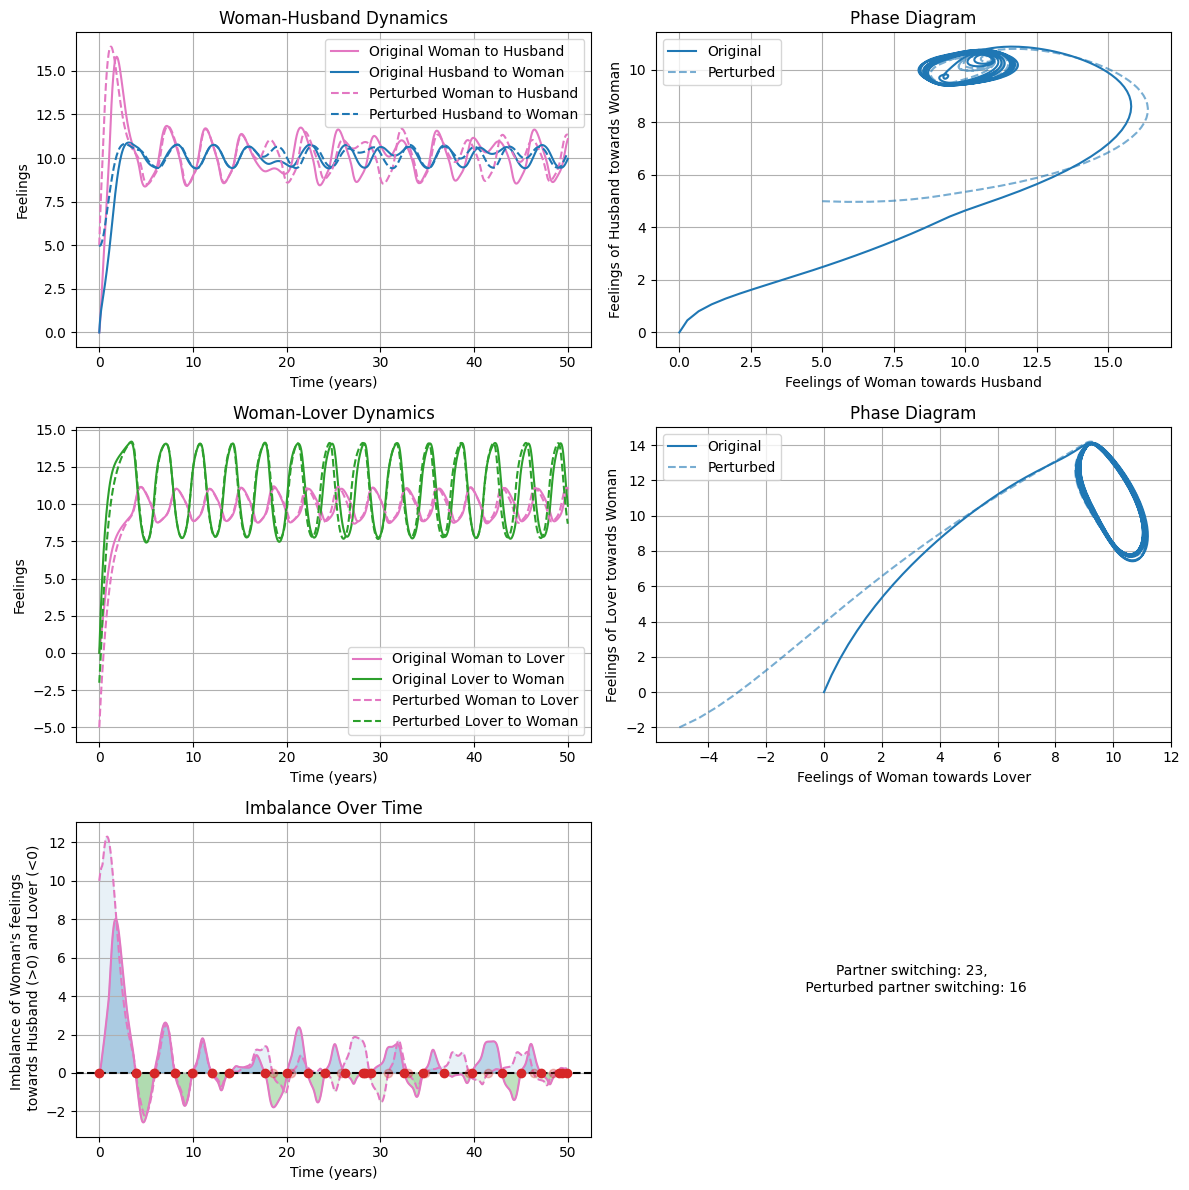

In [3]:
t = np.linspace(0, 50, 1000)

# Original dynamics
initial_conditions = [0, 0, 0, 0]
solution_original = odeint(tripert.love_dynamics, initial_conditions, t, args=(params,))

# Perturbed dynamics
initial_perturbations = {0: 5,  # x12: initial feelings of Kathe towards Jules
                            1: -5,  # x13: initial feelings of Kathe towards Jim
                            2: 5,  # x21: initial feelings of Jules towards Kathe
                            3: -2   # x31: initial feelings of Jim towards Kathe
                            }
parameter_perturbations = {0: 0,    # alpha1: forgetting coefficient for Kathe (years^-1)
                            1: 0,    # alpha2: forgetting coefficient for Jules (years^-1)
                            2: 0,    # alpha3: forgetting coefficient for Jim (years^-1)
                            3: 0,    # beta21: reaction coefficient to love for Jules to Kathe's love(years^-1)
                            4: 0,    # beta12: reaction coefficient to love for Kathe to Jules love (years^-1)
                            5: 0,    # beta13: reaction coefficient to love for Kathe to Jim's love (years^-1)
                            6: 0,    # beta31: reaction coefficient to love for Jim to Kathe's love (years^-1)
                            7: 0,    # gamma1: reaction coefficient to appeal for Kathe (years^-1)
                            8: 0,    # gamma2: reaction coefficient to appeal for Jules (years^-1)
                            9: 0,    # gamma3: reaction coefficient to appeal for Jim (years^-1)
                            10: 0,   # epsilon: sensitivity of reaction to love for Kathe (coupling constant)
                            11: 0,   # delta: sensitivity of reaction to love for Jules and Jim (coupling constant)
                            12: 0,   # A1: appeal of Kathe (dimensionless)
                            13: 0,   # A2: appeal of Jules (dimensionless)
                            14: 0,   # A3: appeal of Jim (dimensionless)
                            15: 0,   # tauI12: insecurity threshold for Kathe's reaction to Jules' love
                            16: 0,   # sigmaL12: sensitivity of reaction to love for Kathe to Jules
                            17: 0,   # sigmaI12: sensitivity of insecurity for Kathe to Jules
                            18: 0,   # tau_S: synergism threshold for Kathe
                            19: 0,   # sigmaS: sensitivity of synergism for Kathe
                            20: 0,   # tauP: platonicity threshold for Jules
                            21: 0,   # p: maximum platonicity for Jules
                            22: 0,   # sigmaP: sensitivity of platonicity for Jules
                            23: 0,   # tauI31: insecurity threshold for Jim's reaction to love
                            24: 0,   # sigmaL31: sensitivity of reaction to love for Jim
                            25: 0    # sigmaI31: sensitivity of insecurity for Jim
                            }

perturbed_initial_conditions = tripert.perturb_initial_conditions(initial_conditions, initial_perturbations)
perturbed_params = tripert.perturb_parameters(params, parameter_perturbations)
solution_perturbed = odeint(tripert.love_dynamics, perturbed_initial_conditions, t, args=(perturbed_params,))

# Plotting
tripert.plot_love_dynamics(t, solution_original, solution_perturbed)

## Heatmap of Normalised Integral Balance

Visualises who "wins" in the end.

A1 Progress: 100%|██████████| 100/100 [00:47<00:00,  2.10it/s]


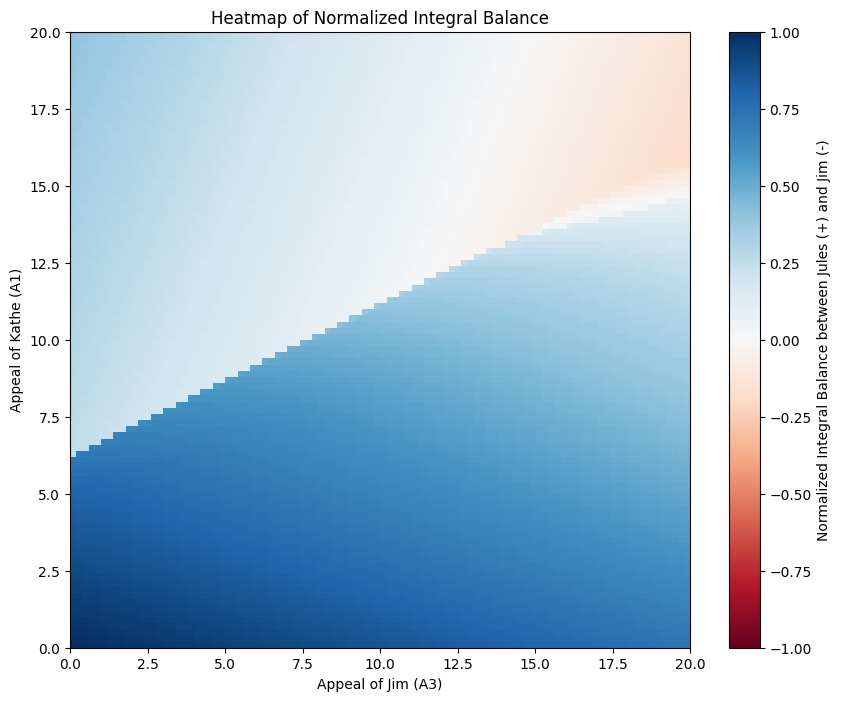

In [ ]:
t = np.linspace(0, 50, 1000)
initial_conditions = [0, 0, 0, 0]
a1_range = np.linspace(0, 20, 100) 
a3_range = np.linspace(0, 20, 100)

""" Increase to 100-250 for a more accurate heatmap """



# Generate heatmap data
heatmap_data = triheat.generate_heatmap_data(a3_range, a1_range, initial_conditions, params, t)

# Plot the heatmap
triheat.plot_integral_balance_heatmap(a3_range, a1_range, heatmap_data)